# Limpieza de «Datos diarios» y «Retención D7»

**RecipePredict AI · Entrega 1 (Python) · Pablo Roldán**

Este notebook pasa de los datos originales (`data/raw/`, capa bronze) a datos limpios (`data/silver/`, capa silver) para dos fuentes:

| Fuente | Qué es una fila | Origen |
|---|---|---|
| `rendimiento_diario.csv` | Un Short en un día: views y engaged views de ese día | YouTube Analytics API (dimensión `day`) |
| `retencion_d7.csv` | Un Short en un punto de su duración (1 %, 2 %, … 100 %): qué parte de la audiencia sigue viendo | YouTube Analytics API (informe de retención) |

También se lee `shorts_y_d7.csv` solo para obtener la ventana D7 de cada vídeo, sus totales D7 oficiales y su duración. Esa tabla la limpia Adriana en su propio notebook.

**D7** = el día de publicación y los 6 días siguientes, en hora del Pacífico (la zona horaria de YouTube Analytics).

**Cómo ejecutarlo:** copiar los tres CSV en `data/raw/` (ver `data/README.md`), instalar `requirements.txt` y ejecutar todas las celdas en orden (*Run All*). No hay pasos manuales.

Secciones: 1. Carga · 2. Diagnóstico · 3. Limpieza · 4. Validación · 5. Guardado · 6. Resultados y conclusiones.

## 1. Carga

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# El notebook funciona tanto si se abre desde notebooks/ como desde la raíz del repositorio.
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
CARPETA_RAW = RAIZ / "data" / "raw"
CARPETA_SILVER = RAIZ / "data" / "silver"

DIAS_D7 = 7          # día de publicación + 6 días siguientes
PUNTOS_CURVA = 100   # la retención se mide en 100 puntos: 1 %, 2 %, ..., 100 % del vídeo

def leer_csv(nombre, fechas):
    # utf-8-sig: los CSV empiezan con una marca BOM que, si no, se pegaría al nombre de la primera columna.
    return pd.read_csv(CARPETA_RAW / nombre, encoding="utf-8-sig", parse_dates=fechas)

diario_raw = leer_csv("rendimiento_diario.csv", ["day", "start_date", "end_date"])
retencion_raw = leer_csv("retencion_d7.csv", ["start_date", "end_date"])
shorts = leer_csv("shorts_y_d7.csv", ["inicio_d7", "fin_d7"])[[
    "video_id", "channel_id", "inicio_d7", "fin_d7",
    "view_count_d7", "engaged_views_d7", "duration_seconds",
]]

# Trabajamos sobre copias: los originales se quedan intactos para la comparación final.
diario = diario_raw.copy()
retencion = retencion_raw.copy()

for nombre, tabla in [("Datos diarios", diario_raw), ("Retención D7", retencion_raw), ("Shorts (referencia)", shorts)]:
    print(f"{nombre}: {tabla.shape[0]} filas × {tabla.shape[1]} columnas")

Datos diarios: 4772 filas × 7 columnas
Retención D7: 9676 filas × 7 columnas
Shorts (referencia): 100 filas × 7 columnas


In [2]:
diario_raw.head()

,channel_id,video_id,day,views,engagedViews,start_date,end_date
0,UCHLtttXxyG5mr8ORkqEiSeA,ALtNIEko9MY,2026-11-16,1126,406,2026-11-16,2026-11-23
1,UCHLtttXxyG5mr8ORkqEiSeA,ALtNIEko9MY,2026-11-17,24,5,2026-11-16,2026-11-23
2,UCHLtttXxyG5mr8ORkqEiSeA,ALtNIEko9MY,2026-11-18,13,3,2026-11-16,2026-11-23
3,UCHLtttXxyG5mr8ORkqEiSeA,ALtNIEko9MY,2026-11-19,17,3,2026-11-16,2026-11-23
4,UCHLtttXxyG5mr8ORkqEiSeA,ALtNIEko9MY,2026-11-20,9,3,2026-11-16,2026-11-23


In [3]:
retencion_raw.head()

,channel_id,video_id,elapsedVideoTimeRatio,audienceWatchRatio,relativeRetentionPerformance,start_date,end_date
0,UCHLtttXxyG5mr8ORkqEiSeA,ALtNIEko9MY,0.01,1.1595,0.49040,2026-11-16,2026-11-22
1,UCHLtttXxyG5mr8ORkqEiSeA,ALtNIEko9MY,0.02,1.1476,0.44715,2026-11-16,2026-11-22
2,UCHLtttXxyG5mr8ORkqEiSeA,ALtNIEko9MY,0.03,1.1357,0.40455,2026-11-16,2026-11-22
3,UCHLtttXxyG5mr8ORkqEiSeA,ALtNIEko9MY,0.04,1.1095,0.36730,2026-11-16,2026-11-22
4,UCHLtttXxyG5mr8ORkqEiSeA,ALtNIEko9MY,0.05,1.1024,0.33765,2026-11-16,2026-11-22


## 2. Diagnóstico

Primero se mira sin cambiar nada. Cada control queda registrado, también los que no encuentran problemas.

### 2.1 Controles comunes a las dos tablas

In [4]:
def controles_basicos(tabla, clave):
    cruce = tabla.merge(shorts[["video_id", "channel_id"]], on="video_id", how="left", suffixes=("", "_ref"))
    return {
        "filas": len(tabla),
        "columnas": tabla.shape[1],
        "valores nulos": int(tabla.isna().sum().sum()),
        f"duplicados por {' + '.join(clave)}": int(tabla.duplicated(clave).sum()),
        "vídeos que no están en shorts_y_d7": int(cruce["channel_id_ref"].isna().sum()),
        "filas con canal distinto al del vídeo": int((cruce["channel_id"] != cruce["channel_id_ref"]).sum()),
        "Shorts sin ninguna fila": len(set(shorts["video_id"]) - set(tabla["video_id"])),
    }

# Redondeamos el punto de la curva: 0.07 puede venir como 0.07000000001 y no se reconocería como duplicado.
retencion["elapsedVideoTimeRatio"] = retencion["elapsedVideoTimeRatio"].round(2)

pd.DataFrame({
    "Datos diarios": controles_basicos(diario, ["video_id", "day"]),
    "Retención D7": controles_basicos(retencion, ["video_id", "elapsedVideoTimeRatio"]),
})

,Datos diarios,Retención D7
filas,4772.0,9676.0
columnas,7.0,7.0
valores nulos,0.0,0.0
duplicados por video_id + day,0.0,NaN
vídeos que no están en shorts_y_d7,0.0,0.0
filas con canal distinto al del vídeo,0.0,0.0
Shorts sin ninguna fila,0.0,3.0
duplicados por video_id + elapsedVideoTimeRatio,NaN,0.0


In [5]:
print(diario.dtypes, '\n'); print(retencion.dtypes)

channel_id                 str
video_id                   str
day             datetime64[us]
views                    int64
engagedViews             int64
start_date      datetime64[us]
end_date        datetime64[us]
dtype: object 

channel_id                                 str
video_id                                   str
elapsedVideoTimeRatio                  float64
audienceWatchRatio                     float64
relativeRetentionPerformance           float64
start_date                      datetime64[us]
end_date                        datetime64[us]
dtype: object


Los tipos son correctos (fechas como fecha, conteos como enteros, ratios como decimales). No hay nulos ni duplicados, y todos los vídeos existen en la tabla de Shorts con su mismo canal. La última fila indica que **3 Shorts no tienen curva de retención**; se analiza en 2.3.

### 2.2 «Datos diarios»: reglas del dominio

In [6]:
diario_d = diario.merge(shorts, on=["video_id", "channel_id"])
diario_d["dia_desde_publicacion"] = (diario_d["day"] - diario_d["inicio_d7"]).dt.days
dentro_d7 = diario_d["dia_desde_publicacion"].between(0, DIAS_D7 - 1)

pd.Series({
    "views o engaged views negativas": int((diario[["views", "engagedViews"]] < 0).sum().sum()),
    "días con más engaged views que views (imposible)": int((diario["engagedViews"] > diario["views"]).sum()),
    "días anteriores a la publicación": int((diario_d["dia_desde_publicacion"] < 0).sum()),
    "filas dentro de D7": int(dentro_d7.sum()),
    "filas posteriores a D7": int((~dentro_d7).sum()),
    "valores distintos de start_date por vídeo (máx.)": int(diario.groupby("video_id")["start_date"].nunique().max()),
}, name="resultado").to_frame()

,resultado
views o engaged views negativas,0
días con más engaged views que views (imposible),0
días anteriores a la publicación,0
filas dentro de D7,528
filas posteriores a D7,4244
valores distintos de start_date por vídeo (máx.),1


In [7]:
# ¿Cuántos de los 7 días de D7 tienen fila? YouTube no devuelve los días con 0 views.
filas_d7 = diario_d[dentro_d7].groupby("video_id").size().reindex(shorts["video_id"], fill_value=0)
print("Número de días con fila dentro de D7 → número de vídeos")
print(filas_d7.value_counts().sort_index().to_string())

Número de días con fila dentro de D7 → número de vídeos
0     1
2     3
3     1
4    18
5    30
6    32
7    15


In [8]:
# Si los días que faltan fueran días con 0 views, la suma de los días que sí hay
# debería coincidir exactamente con el total D7 oficial de cada vídeo.
suma_d7 = (diario_d[dentro_d7].groupby("video_id")[["views", "engagedViews"]].sum()
           .reindex(shorts["video_id"], fill_value=0)
           .join(shorts.set_index("video_id")[["view_count_d7", "engaged_views_d7"]]))
con_total = suma_d7.dropna(subset=["view_count_d7"])
cuadra = ((con_total["views"] == con_total["view_count_d7"]) &
          (con_total["engagedViews"] == con_total["engaged_views_d7"]))
print(f"Vídeos con total D7 oficial: {len(con_total)}")
print(f"Vídeos cuya suma diaria coincide con el total oficial: {cuadra.sum()}")
print(f"Vídeos sin total D7 (ventana todavía abierta): {list(suma_d7.index[suma_d7['view_count_d7'].isna()])}")

Vídeos con total D7 oficial: 99
Vídeos cuya suma diaria coincide con el total oficial: 99
Vídeos sin total D7 (ventana todavía abierta): ['ALtNIEko9MY']


**Qué revela:**

- No hay valores imposibles.
- Solo 15 vídeos tienen fila en los 7 días de D7. Pero **la suma de los días que sí hay coincide con el total oficial en los 99 vídeos que lo tienen**. Eso demuestra que los días que faltan son días con 0 views que YouTube no devuelve, no datos perdidos. Se pueden rellenar con 0 de forma justificada.
- El vídeo `ALtNIEko9MY` se publicó el 16/11/2026 y su semana D7 aún no estaba cerrada al extraer los datos. No se rellena: no sabemos si le falta un día o si tuvo 0 views.
- La mayoría de las filas son **posteriores a D7**: la consulta pidió todo el historial del vídeo. No son un error. Se conservan marcadas, porque la capa silver debe conservar el detalle útil.
- `start_date` y `end_date` son las fechas de la consulta a la API, no del vídeo, y tienen un único valor por vídeo. No aportan información.

### 2.3 «Retención D7»: reglas del dominio

In [9]:
retencion_d = retencion.merge(shorts, on=["video_id", "channel_id"])
puntos = retencion.groupby("video_id").size()

pd.Series({
    "filas medidas fuera de la ventana D7 del vídeo": int(((retencion_d["start_date"] != retencion_d["inicio_d7"]) |
                                                          (retencion_d["end_date"] != retencion_d["fin_d7"])).sum()),
    "punto de la curva fuera de 0.01–1": int((~retencion["elapsedVideoTimeRatio"].between(0.01, 1)).sum()),
    "retención relativa fuera de 0–1": int((~retencion["relativeRetentionPerformance"].between(0, 1)).sum()),
    "retención de audiencia negativa": int((retencion["audienceWatchRatio"] < 0).sum()),
    "puntos con retención de audiencia > 1": int((retencion["audienceWatchRatio"] > 1).sum()),
    "vídeos con algún punto > 1": int(retencion.loc[retencion["audienceWatchRatio"] > 1, "video_id"].nunique()),
    "curvas con 100 puntos": int((puntos == PUNTOS_CURVA).sum()),
    "curvas incompletas": int((puntos < PUNTOS_CURVA).sum()),
}, name="resultado").to_frame()

,resultado
filas medidas fuera de la ventana D7 del vídeo,0
punto de la curva fuera de 0.01–1,0
retención relativa fuera de 0–1,0
retención de audiencia negativa,0
puntos con retención de audiencia > 1,1090
vídeos con algún punto > 1,96
curvas con 100 puntos,96
curvas incompletas,1


In [10]:
incompletas = puntos[puntos < PUNTOS_CURVA]
for video_id, n in incompletas.items():
    ultimo = retencion.loc[retencion["video_id"] == video_id, "elapsedVideoTimeRatio"].max()
    print(f"Curva incompleta: {video_id} tiene {n} puntos y termina en el {ultimo:.0%} del vídeo")

sin_curva = shorts[~shorts["video_id"].isin(retencion["video_id"])]
print("\nShorts sin curva de retención:")
sin_curva[["video_id", "channel_id", "view_count_d7", "duration_seconds"]]

Curva incompleta: d5ve_DRKmfk tiene 76 puntos y termina en el 76% del vídeo

Shorts sin curva de retención:


,video_id,channel_id,view_count_d7,duration_seconds
66,XiLRVUjWdpw,UCHLtttXxyG5mr8ORkqEiSeA,0.0,77
70,CBdWEbmLHi4,UCHLtttXxyG5mr8ORkqEiSeA,8.0,81
98,nQpw6XUy0yw,UCKZhrtzlr9NcL_k_5no9mJQ,6.0,15


**Qué revela:**

- Todas las curvas se midieron en la misma ventana D7 que las views: las dos tablas son comparables.
- **Retención de audiencia mayor que 1 en 96 vídeos:** parece un error, pero **es un valor válido**. En los Shorts el vídeo se repite en bucle y parte del público vuelve a ver un tramo, así que en un punto puede haber más reproducciones que espectadores. Se conserva.
- **3 Shorts sin curva:** tuvieron 0, 6 y 8 views en D7. YouTube no calcula la retención con tan poca audiencia. No es un fallo de la extracción y no se puede recuperar.
- **1 curva incompleta** (`d5ve_DRKmfk`, hasta el 76 %). No se inventan los puntos que faltan; se marca.

### 2.4 EDA de las variables principales

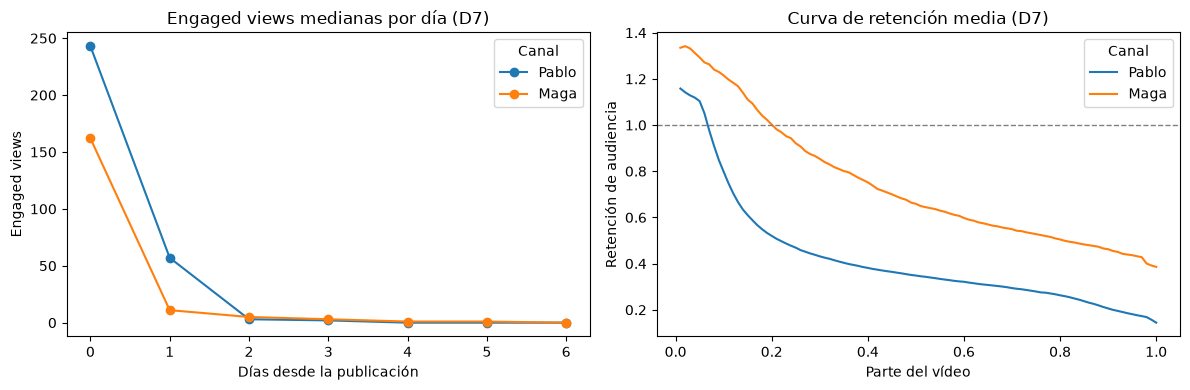

In [11]:
# Engaged views mediana por día desde la publicación, por canal (solo D7, con los días sin fila contados como 0).
completo = (shorts.loc[shorts["view_count_d7"].notna(), ["video_id", "channel_id"]]
            .merge(pd.DataFrame({"dia_desde_publicacion": range(DIAS_D7)}), how="cross"))
por_dia = (completo.merge(diario_d[dentro_d7][["video_id", "dia_desde_publicacion", "engagedViews"]],
                          on=["video_id", "dia_desde_publicacion"], how="left")
           .fillna({"engagedViews": 0}))

nombres_canal = {"UCHLtttXxyG5mr8ORkqEiSeA": "Pablo", "UCKZhrtzlr9NcL_k_5no9mJQ": "Maga"}
fig, ejes = plt.subplots(1, 2, figsize=(12, 4))

(por_dia.groupby(["dia_desde_publicacion", "channel_id"])["engagedViews"].median()
 .unstack().rename(columns=nombres_canal).plot(marker="o", ax=ejes[0]))
ejes[0].set(title="Engaged views medianas por día (D7)", xlabel="Días desde la publicación", ylabel="Engaged views")

(retencion.groupby(["elapsedVideoTimeRatio", "channel_id"])["audienceWatchRatio"].mean()
 .unstack().rename(columns=nombres_canal).plot(ax=ejes[1]))
ejes[1].axhline(1, color="grey", linestyle="--", linewidth=1)
ejes[1].set(title="Curva de retención media (D7)", xlabel="Parte del vídeo", ylabel="Retención de audiencia")
for eje in ejes:
    eje.legend(title="Canal")
plt.tight_layout()
plt.show()

In [12]:
por_video = por_dia.groupby(["channel_id", "video_id"])["engagedViews"]
resumen = pd.DataFrame({
    "% de engaged views D7 en el día 0": por_dia[por_dia["dia_desde_publicacion"] == 0]
        .groupby("channel_id")["engagedViews"].sum() / por_dia.groupby("channel_id")["engagedViews"].sum() * 100,
    "Shorts con datos D7": por_dia.groupby("channel_id")["video_id"].nunique(),
}).rename(index=nombres_canal).round(1)
resumen

,% de engaged views D7 en el día 0,Shorts con datos D7
channel_id,,
Pablo,58.7,77
Maga,44.7,22


**Qué revela:** casi todo el rendimiento se concentra en los primeros días, y sobre todo en el día de publicación. Esto confirma que una ventana de 7 días basta para medir el éxito de un Short. Las curvas de retención empiezan por encima de 1 (repeticiones) y bajan a lo largo del vídeo; la forma es la esperada.

## 3. Limpieza

Cada transformación responde a un hallazgo del diagnóstico.

### 3.1 «Datos diarios»

In [13]:
# (a) start_date y end_date son fechas de la consulta, no del vídeo → se eliminan.
# (b) Nombres en minúsculas con guion bajo, como el resto del proyecto.
diario = diario.drop(columns=["start_date", "end_date"]).rename(
    columns={"day": "fecha", "engagedViews": "engaged_views"})

# (c) Día relativo a la publicación, para poder comparar vídeos publicados en fechas distintas.
diario = diario.merge(shorts[["video_id", "inicio_d7"]], on="video_id")
diario["dia_desde_publicacion"] = (diario["fecha"] - diario["inicio_d7"]).dt.days
diario["fila_rellenada"] = False

# (d) Rellenar con 0 los días sin fila dentro de D7, solo en vídeos con total D7 confirmado
#     (en 2.2 se demostró que esos días tuvieron 0 views).
nuevas = []
for _, video in shorts[shorts["view_count_d7"].notna()].iterrows():
    dias_existentes = set(diario.loc[diario["video_id"] == video["video_id"], "dia_desde_publicacion"])
    for dia in range(DIAS_D7):
        if dia not in dias_existentes:
            nuevas.append({"channel_id": video["channel_id"], "video_id": video["video_id"],
                           "fecha": video["inicio_d7"] + pd.Timedelta(days=dia), "views": 0, "engaged_views": 0,
                           "dia_desde_publicacion": dia, "fila_rellenada": True})
diario = pd.concat([diario, pd.DataFrame(nuevas)], ignore_index=True)
print(f"Días rellenados con 0: {len(nuevas)}")

# (e) Marcar los días de la ventana D7. Los posteriores se conservan para posibles análisis a largo plazo.
diario["en_ventana_d7"] = diario["dia_desde_publicacion"].between(0, DIAS_D7 - 1)

diario_silver = (diario[["channel_id", "video_id", "fecha", "dia_desde_publicacion", "en_ventana_d7",
                         "views", "engaged_views", "fila_rellenada"]]
                 .astype({"views": int, "engaged_views": int, "dia_desde_publicacion": int})
                 .sort_values(["channel_id", "video_id", "fecha"]).reset_index(drop=True))
diario_silver.head(8)

Días rellenados con 0: 171


,channel_id,video_id,fecha,dia_desde_publicacion,en_ventana_d7,views,engaged_views,fila_rellenada
0,UCHLtttXxyG5mr8ORkqEiSeA,-g26rmJQpbc,2025-06-17,0,True,786,234,False
1,UCHLtttXxyG5mr8ORkqEiSeA,-g26rmJQpbc,2025-06-18,1,True,560,273,False
2,UCHLtttXxyG5mr8ORkqEiSeA,-g26rmJQpbc,2025-06-19,2,True,10,3,False
3,UCHLtttXxyG5mr8ORkqEiSeA,-g26rmJQpbc,2025-06-20,3,True,1,0,False
4,UCHLtttXxyG5mr8ORkqEiSeA,-g26rmJQpbc,2025-06-21,4,True,2,1,False
5,UCHLtttXxyG5mr8ORkqEiSeA,-g26rmJQpbc,2025-06-22,5,True,2,1,False
6,UCHLtttXxyG5mr8ORkqEiSeA,-g26rmJQpbc,2025-06-23,6,True,0,0,True
7,UCHLtttXxyG5mr8ORkqEiSeA,-g26rmJQpbc,2025-06-25,8,False,1,0,False


### 3.2 «Retención D7»

In [14]:
# (a) start_date y end_date ya se comprobaron en 2.3 (coinciden con D7) → se eliminan.
# (b) Nombres en español y en el estilo del proyecto.
retencion_silver = retencion.drop(columns=["start_date", "end_date"]).rename(columns={
    "elapsedVideoTimeRatio": "punto_video",
    "audienceWatchRatio": "retencion_audiencia",
    "relativeRetentionPerformance": "retencion_relativa",
})

# (c) Segundo del vídeo en el que cae cada punto: más fácil de interpretar que un porcentaje
#     (por ejemplo, para estudiar el gancho de los primeros 3 segundos).
retencion_silver = retencion_silver.merge(shorts[["video_id", "duration_seconds"]], on="video_id")
retencion_silver["segundo_video"] = (retencion_silver["punto_video"] * retencion_silver["duration_seconds"]).round(1)

# (d) Redondeo a 4 decimales: elimina el ruido de coma flotante sin perder precisión útil.
retencion_silver[["retencion_audiencia", "retencion_relativa"]] = (
    retencion_silver[["retencion_audiencia", "retencion_relativa"]].round(4))

# No se eliminan los valores > 1 (son válidos) ni se inventan los puntos que faltan.
retencion_silver = (retencion_silver[["channel_id", "video_id", "punto_video", "segundo_video",
                                      "retencion_audiencia", "retencion_relativa"]]
                    .sort_values(["channel_id", "video_id", "punto_video"]).reset_index(drop=True))
retencion_silver.head()

,channel_id,video_id,punto_video,segundo_video,retencion_audiencia,retencion_relativa
0,UCHLtttXxyG5mr8ORkqEiSeA,-g26rmJQpbc,0.01,0.7,1.4004,0.6485
1,UCHLtttXxyG5mr8ORkqEiSeA,-g26rmJQpbc,0.02,1.5,1.3770,0.5886
2,UCHLtttXxyG5mr8ORkqEiSeA,-g26rmJQpbc,0.03,2.2,1.3535,0.5406
3,UCHLtttXxyG5mr8ORkqEiSeA,-g26rmJQpbc,0.04,3.0,1.3398,0.5163
4,UCHLtttXxyG5mr8ORkqEiSeA,-g26rmJQpbc,0.05,3.7,1.3320,0.5078


### 3.3 Tabla de calidad por vídeo

Una fila por Short que resume lo que se sabe de sus datos. Así, en el EDA y en el modelo se puede filtrar fácilmente (por ejemplo, excluir los vídeos sin curva de retención).

In [15]:
d7 = diario_silver[diario_silver["en_ventana_d7"]]
calidad = shorts[["channel_id", "video_id"]].copy()
calidad["ventana_d7_cerrada"] = shorts["view_count_d7"].notna()
calidad["dias_d7_con_dato_original"] = calidad["video_id"].map(
    d7[~d7["fila_rellenada"]].groupby("video_id").size()).fillna(0).astype(int)
calidad["dias_d7_rellenados_con_0"] = calidad["video_id"].map(
    d7[d7["fila_rellenada"]].groupby("video_id").size()).fillna(0).astype(int)
calidad["puntos_retencion"] = calidad["video_id"].map(
    retencion_silver.groupby("video_id").size()).fillna(0).astype(int)
calidad["curva_retencion_completa"] = calidad["puntos_retencion"] == PUNTOS_CURVA
calidad = calidad.sort_values(["channel_id", "video_id"]).reset_index(drop=True)
calidad[~calidad["ventana_d7_cerrada"] | ~calidad["curva_retencion_completa"]]

,channel_id,video_id,ventana_d7_cerrada,dias_d7_con_dato_original,dias_d7_rellenados_con_0,puntos_retencion,curva_retencion_completa
14,UCHLtttXxyG5mr8ORkqEiSeA,ALtNIEko9MY,False,6,0,100,True
17,UCHLtttXxyG5mr8ORkqEiSeA,CBdWEbmLHi4,True,5,2,0,False
40,UCHLtttXxyG5mr8ORkqEiSeA,XiLRVUjWdpw,True,0,7,0,False
44,UCHLtttXxyG5mr8ORkqEiSeA,d5ve_DRKmfk,True,4,3,76,False
95,UCKZhrtzlr9NcL_k_5no9mJQ,nQpw6XUy0yw,True,4,3,0,False


## 4. Validación

Si alguna regla falla, el notebook se detiene con un error. Así no se puede guardar una capa silver incorrecta.

In [16]:
# Datos diarios
assert not diario_silver.duplicated(["video_id", "fecha"]).any(), "Hay días duplicados"
assert diario_silver.notna().all().all(), "Hay nulos"
assert (diario_silver[["views", "engaged_views"]] >= 0).all().all(), "Hay valores negativos"
assert (diario_silver["engaged_views"] <= diario_silver["views"]).all(), "Engaged views > views"

suma = (diario_silver[diario_silver["en_ventana_d7"]].groupby("video_id")[["views", "engaged_views"]].sum()
        .join(shorts.set_index("video_id")[["view_count_d7", "engaged_views_d7"]]).dropna())
assert (suma["views"] == suma["view_count_d7"]).all(), "La suma D7 de views no cuadra"
assert (suma["engaged_views"] == suma["engaged_views_d7"]).all(), "La suma D7 de engaged views no cuadra"
dias_por_video = diario_silver[diario_silver["en_ventana_d7"]].groupby("video_id").size()
assert (dias_por_video[suma.index] == DIAS_D7).all(), "Algún vídeo cerrado no tiene sus 7 días"

# Retención D7
assert not retencion_silver.duplicated(["video_id", "punto_video"]).any(), "Hay puntos duplicados"
assert retencion_silver.notna().all().all(), "Hay nulos"
assert retencion_silver["retencion_relativa"].between(0, 1).all(), "Retención relativa fuera de 0–1"
assert (retencion_silver["retencion_audiencia"] >= 0).all(), "Retención negativa"

print("✅ Todas las validaciones se cumplen")
print(f"   {len(suma)} de {len(shorts)} vídeos tienen sus 7 días D7 completos y cuadran con el total oficial")

✅ Todas las validaciones se cumplen
   99 de 100 vídeos tienen sus 7 días D7 completos y cuadran con el total oficial


### Comparación antes y después

In [17]:
antes_despues = pd.DataFrame([
    {"Tabla": "Datos diarios", "Filas antes": len(diario_raw), "Filas después": len(diario_silver),
     "Columnas antes": diario_raw.shape[1], "Columnas después": diario_silver.shape[1],
     "Problemas encontrados": "días con 0 views omitidos por YouTube; columnas de la consulta sin información; días fuera de D7 sin marcar",
     "Acciones": f"+{len(nuevas)} días con 0 (justificado por las sumas); −2 columnas; +3 columnas (día relativo, marca D7, marca de relleno)",
     "Pendiente": "ALtNIEko9MY: ventana D7 abierta, sin total"},
    {"Tabla": "Retención D7", "Filas antes": len(retencion_raw), "Filas después": len(retencion_silver),
     "Columnas antes": retencion_raw.shape[1], "Columnas después": retencion_silver.shape[1],
     "Problemas encontrados": "columnas de la consulta sin información; ruido de coma flotante; 3 Shorts sin curva; 1 curva incompleta",
     "Acciones": "−2 columnas; +1 columna (segundo del vídeo); redondeo; nombres en español",
     "Pendiente": "3 Shorts sin curva y 1 curva hasta el 76 % (marcados en calidad_por_video)"},
])
antes_despues

,Tabla,Filas antes,Filas después,Columnas antes,Columnas después,Problemas encontrados,Acciones,Pendiente
0,Datos diarios,4772,4943,7,8,días con 0 views omitidos por YouTube; columna...,+171 días con 0 (justificado por las sumas); −...,"ALtNIEko9MY: ventana D7 abierta, sin total"
1,Retención D7,9676,9676,7,6,columnas de la consulta sin información; ruido...,−2 columnas; +1 columna (segundo del vídeo); r...,3 Shorts sin curva y 1 curva hasta el 76 % (ma...


## 5. Guardado (capa silver)

In [18]:
CARPETA_SILVER.mkdir(parents=True, exist_ok=True)
salidas = {
    "rendimiento_diario_silver.csv": diario_silver,
    "retencion_d7_silver.csv": retencion_silver,
    "calidad_por_video.csv": calidad,
}
for nombre, tabla in salidas.items():
    tabla.to_csv(CARPETA_SILVER / nombre, index=False)
    print(f"Guardado data/silver/{nombre}: {len(tabla)} filas")

Guardado data/silver/rendimiento_diario_silver.csv: 4943 filas
Guardado data/silver/retencion_d7_silver.csv: 9676 filas
Guardado data/silver/calidad_por_video.csv: 100 filas


## 6. Resultados y conclusiones

- **Los datos sirven para el proyecto.** Las views diarias permiten calcular el KPI principal (engaged views D7) en 99 de 100 Shorts, y cuadran con el total oficial. La curva de retención permite calcular el KPI secundario en 96 Shorts con curva completa.
- **La ventana de 7 días es adecuada:** la mayor parte del rendimiento ocurre en los primeros días tras la publicación.
- **Limitaciones:**
  - Muestra pequeña y desequilibrada: 78 Shorts de Pablo y 22 de Maga.
  - Los Shorts de Maga son de 2022–2024. Antes del cambio de YouTube de 2025 las views y las engaged views son iguales, así que **el KPI debe usar engaged views**, que son comparables entre épocas.
  - Si el modelo se evalúa separando por fecha, todos los Shorts de Maga quedan en entrenamiento.
  - 3 Shorts no tienen retención por tener muy pocas views. Si se excluyen del análisis de retención, la muestra se sesga ligeramente hacia los vídeos con más audiencia.
- **Siguiente paso (Entrega 2, SQL):** cargar estas tablas silver y unirlas con la tabla de Shorts limpia por `video_id`. Las agregaciones (totales D7, retención media) se calculan en la capa gold.